# 05. 듀오링고 첫 레슨·후속 학습 가설 분석

## 분석 목적

04번 퍼널 분석에서 확인한 첫 레슨 미완료와 완료 후 미진행에 대해, H1~H5의 집단별 전환율 차이 확인.

- 입력: `funnel_users.csv`, `event_logs_preprocessed.csv`
- 분석 단위: 사용자 1명당 1행. 같은 행동이 여러 번 발생해도 경험 여부는 1회로 집계
- 결과: 집단별 비율, 비율 차이(%p), 카이제곱 검정, 다중비교 보정, 해석

> 가상 데이터의 행동 차이를 분석하는 연습이며, 실제 듀오링고의 문제 또는 인과 효과를 검증하는 연구가 아님.


## 1. 라이브러리 및 데이터 호출

기존 프로젝트 경로 유지. 이번에 추가한 `scipy`는 카이제곱 검정에 사용하며, 설치되어 있지 않다면 프로젝트 터미널에서 `uv add scipy` 실행 후 노트북 실행.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency


In [2]:
# 프로젝트 최상위 경로: 기존 노트북과 동일한 위치
ROOT = Path(r"C:\Users\joon5\Documents\github\duolingo-funnel-analysis")

DATA_PROCESSED_DIR = ROOT / "data" / "processed"
FUNNEL_USERS_PATH = DATA_PROCESSED_DIR / "funnel_users.csv"
EVENT_PROCESSED_PATH = DATA_PROCESSED_DIR / "event_logs_preprocessed.csv"

# 04번에서 저장한 도달 시각과 단계 플래그 재사용
funnel_users = pd.read_csv(
    FUNNEL_USERS_PATH,
    parse_dates=[
        "first_seen_at", "first_started_at", "first_lesson_deadline",
        "first_answer_at", "halfway_at", "first_completed_at", "second_started_at",
    ],
)
df_events = pd.read_csv(EVENT_PROCESSED_PATH, parse_dates=["event_time"])

print("사용자:", len(funnel_users), "명")
print("이벤트:", len(df_events), "건")


사용자: 10000 명
이벤트: 320705 건


## 2. 가설 및 비교 기준

04번에서 정의한 24시간 내 첫 레슨 완료(`step_4`)와 완료 후 7일 내 두 번째 시작(`step_5`)을 그대로 결과 변수로 사용.

| 가설 | 예상 방향 | 분석 대상 | 비교 집단 |
| --- | --- | --- | --- |
| H1 | 구독 안내 노출자의 두 번째 시작률이 낮음 | 첫 레슨 완료자 | 미노출 / 노출 |
| H2 | 말하기 건너뛰기 경험자의 완료율이 낮음 | 첫 레슨 시작자 | 미경험 / 경험 |
| H3 | 완료 시 에너지 부족 사용자의 두 번째 시작률이 낮음 | 첫 레슨 완료자 | 에너지 6 이상 / 0~5 |
| H4 | 힌트 사용자의 완료율이 높음 | 첫 레슨 시작자 | 미사용 / 사용 |
| H5 | 일일 목표가 길수록 두 번째 시작률이 높음 | 첫 레슨 완료자 | 3 / 10 / 15 / 30분 |

**행동의 시간 범위**

- H2·H4: 같은 첫 레슨 시도에서 시작 후 24시간 이내이며, 완료자라면 완료 시각보다 앞선 행동만 인정
- H1: 첫 완료 이후 7일 이내 노출을 인정하되, 두 번째 시작자는 두 번째 시작 시각보다 앞선 노출만 포함
- H2 보조 비교: 말하기 문제 화면을 본 사용자끼리 비교
- H4 보조 비교: 오답 경험자끼리 비교

**통계 해석 기준**

- 사용자별 전환·미전환 인원으로 Pearson 카이제곱 독립성 검정. 가설의 높음·낮음 방향은 관찰된 비율 차이와 함께 확인
- 5개 주분석과 2개 보조 비교, 총 **7개 검정**에 Bonferroni 보정 적용: `보정 p = min(원 p × 7, 1)`. 보정 p < 0.05를 집단 차이의 통계적 근거로 사용
- Cramér's V는 연관 정도, 비율 차이(%p)는 관찰된 차이의 크기로 해석. 유의성만으로 실무적 중요도나 인과 효과를 판단하지 않음
- H5의 카이제곱 검정은 4개 집단의 차이를 확인하며, 증가 추세 자체를 검정하는 방법과 구분


## 3. 가설 분석용 행동 변수 생성

04번의 퍼널 결과는 다시 계산하지 않고, 유효한 시간 범위에서 관찰된 행동 경험 여부만 추가.


In [3]:
# 기존 퍼널 표의 복사본에 분석 변수 추가
analysis_users = funnel_users.copy()

# 같은 첫 레슨 시도의 이벤트와 기준 시각 연결
first_behavior_events = pd.merge(
    df_events[df_events["lesson_number"] == 1],
    analysis_users[[
        "user_id", "lesson_attempt_id", "first_started_at",
        "first_lesson_deadline", "first_completed_at",
    ]],
    on=["user_id", "lesson_attempt_id"],
    how="inner",
)

# 시작 후 24시간 이내이며, 완료했다면 완료 이전의 행동만 유지
first_behavior_events = first_behavior_events[
    (first_behavior_events["event_time"] >= first_behavior_events["first_started_at"]) &
    (first_behavior_events["event_time"] <= first_behavior_events["first_lesson_deadline"]) &
    (first_behavior_events["first_completed_at"].isna() |
     (first_behavior_events["event_time"] < first_behavior_events["first_completed_at"]))
]

# 말하기 건너뛰기 및 말하기 문제 조회 경험 여부
analysis_users["speaking_skipped"] = analysis_users["user_id"].isin(
    first_behavior_events.loc[
        (first_behavior_events["event_name"] == "question_skipped") &
        (first_behavior_events["question_type"] == "speaking"), "user_id"
    ]
)
analysis_users["speaking_viewed"] = analysis_users["user_id"].isin(
    first_behavior_events.loc[
        (first_behavior_events["event_name"] == "question_viewed") &
        (first_behavior_events["question_type"] == "speaking"), "user_id"
    ]
)

# 힌트 사용 및 오답 경험 여부
analysis_users["hint_used"] = analysis_users["user_id"].isin(
    first_behavior_events.loc[first_behavior_events["event_name"] == "hint_used", "user_id"]
)
analysis_users["wrong_experienced"] = analysis_users["user_id"].isin(
    first_behavior_events.loc[
        (first_behavior_events["event_name"] == "answer_submitted") &
        (first_behavior_events["is_correct"] == 0), "user_id"
    ]
)


In [4]:
# 구독 안내는 시도 ID가 비어 있어 사용자 ID와 완료 시각으로 연결
offer_events = pd.merge(
    df_events[
        (df_events["event_name"] == "subscription_offer_viewed") &
        (df_events["lesson_number"] == 1)
    ],
    analysis_users[["user_id", "first_completed_at", "second_started_at"]],
    on="user_id",
    how="inner",
)

# 첫 완료 이후 7일 이내이면서 두 번째 레슨 시작 이전의 노출만 인정
valid_offer_events = offer_events[
    (offer_events["event_time"] >= offer_events["first_completed_at"]) &
    (offer_events["event_time"] <= offer_events["first_completed_at"] + pd.Timedelta(days=7)) &
    (offer_events["second_started_at"].isna() |
     (offer_events["event_time"] < offer_events["second_started_at"]))
]
analysis_users["subscription_viewed"] = analysis_users["user_id"].isin(
    valid_offer_events["user_id"]
)

# 후속 시작률 분석은 첫 레슨 완료자로 한정
completed_users = analysis_users[analysis_users["step_4"]].copy()
completed_users["energy_low"] = completed_users["energy_remaining"] <= 5


## 4. 집단별 전환율 비교

### 4.1 H1: 구독 안내 노출과 두 번째 레슨 시작

첫 완료자 안에서 미노출자와 노출자의 두 번째 시작률 비교. 차이는 **노출 − 미노출** 기준으로 계산.


In [5]:
# 구독 안내 노출 여부별 두 번째 시작률
h1_summary = completed_users.groupby("subscription_viewed")["step_5"].agg(["count", "sum"])
h1_summary = h1_summary.reindex([False, True])
h1_summary.columns = ["사용자 수", "전환자 수"]
h1_summary["전환율(%)"] = h1_summary["전환자 수"] / h1_summary["사용자 수"] * 100
h1_summary.index = ["미노출", "노출"]
h1_difference = h1_summary.loc["노출", "전환율(%)"] - h1_summary.loc["미노출", "전환율(%)"]

display(h1_summary.round(2))
print("노출 - 미노출 차이:", round(h1_difference, 2), "%p")


,사용자 수,전환자 수,전환율(%)
미노출,2634,1277,48.48
노출,3851,1538,39.94


노출 - 미노출 차이: -8.54 %p


### 4.2 H2: 말하기 건너뛰기와 첫 레슨 완료

전체 첫 시작자 비교 후, 말하기 문제 화면을 본 사용자만 대상으로 보조 비교. 차이는 **건너뛰기 경험 − 미경험** 기준.


In [6]:
# 전체 시작자의 말하기 건너뛰기 여부별 완료율
h2_summary = analysis_users.groupby("speaking_skipped")["step_4"].agg(["count", "sum"])
h2_summary = h2_summary.reindex([False, True])
h2_summary.columns = ["사용자 수", "전환자 수"]
h2_summary["전환율(%)"] = h2_summary["전환자 수"] / h2_summary["사용자 수"] * 100
h2_summary.index = ["미경험", "건너뛰기 경험"]
h2_difference = h2_summary.iloc[1]["전환율(%)"] - h2_summary.iloc[0]["전환율(%)"]

print("[전체 첫 레슨 시작자]")
display(h2_summary.round(2))
print("경험 - 미경험 차이:", round(h2_difference, 2), "%p")

# 말하기 문제를 조회한 사용자끼리 추가 비교
speaking_users = analysis_users[analysis_users["speaking_viewed"]]
h2_speaking_summary = speaking_users.groupby("speaking_skipped")["step_4"].agg(["count", "sum"])
h2_speaking_summary = h2_speaking_summary.reindex([False, True])
h2_speaking_summary.columns = ["사용자 수", "전환자 수"]
h2_speaking_summary["전환율(%)"] = (
    h2_speaking_summary["전환자 수"] / h2_speaking_summary["사용자 수"] * 100
)
h2_speaking_summary.index = ["미경험", "건너뛰기 경험"]
h2_speaking_difference = h2_speaking_summary.iloc[1]["전환율(%)"] - h2_speaking_summary.iloc[0]["전환율(%)"]

print("[보조: 말하기 문제 조회자]")
display(h2_speaking_summary.round(2))
print("경험 - 미경험 차이:", round(h2_speaking_difference, 2), "%p")


[전체 첫 레슨 시작자]


,사용자 수,전환자 수,전환율(%)
미경험,8493,5660,66.64
건너뛰기 경험,1507,825,54.74


경험 - 미경험 차이: -11.9 %p
[보조: 말하기 문제 조회자]


,사용자 수,전환자 수,전환율(%)
미경험,7244,5411,74.70
건너뛰기 경험,1507,825,54.74


경험 - 미경험 차이: -19.95 %p


### 4.3 H3: 완료 시 에너지 잔량과 두 번째 레슨 시작

첫 완료 시 에너지 **0~5를 부족**, **6 이상을 여유**로 구분. 차이는 **부족 − 여유** 기준.


In [7]:
# 에너지 부족 여부별 두 번째 시작률
h3_summary = completed_users.groupby("energy_low")["step_5"].agg(["count", "sum"])
h3_summary = h3_summary.reindex([False, True])
h3_summary.columns = ["사용자 수", "전환자 수"]
h3_summary["전환율(%)"] = h3_summary["전환자 수"] / h3_summary["사용자 수"] * 100
h3_summary.index = ["여유 (6 이상)", "부족 (0~5)"]
h3_difference = h3_summary.iloc[1]["전환율(%)"] - h3_summary.iloc[0]["전환율(%)"]

display(h3_summary.round(2))
print("부족 - 여유 차이:", round(h3_difference, 2), "%p")


,사용자 수,전환자 수,전환율(%)
여유 (6 이상),4919,2328,47.33
부족 (0~5),1566,487,31.10


부족 - 여유 차이: -16.23 %p


### 4.4 H4: 힌트 사용과 첫 레슨 완료

전체 첫 시작자 비교 후, 힌트를 사용할 기회와 관계가 있는 오답 경험자끼리 보조 비교. 차이는 **사용 − 미사용** 기준.


In [8]:
# 전체 시작자의 힌트 사용 여부별 완료율
h4_summary = analysis_users.groupby("hint_used")["step_4"].agg(["count", "sum"])
h4_summary = h4_summary.reindex([False, True])
h4_summary.columns = ["사용자 수", "전환자 수"]
h4_summary["전환율(%)"] = h4_summary["전환자 수"] / h4_summary["사용자 수"] * 100
h4_summary.index = ["힌트 미사용", "힌트 사용"]
h4_difference = h4_summary.iloc[1]["전환율(%)"] - h4_summary.iloc[0]["전환율(%)"]

print("[전체 첫 레슨 시작자]")
display(h4_summary.round(2))
print("사용 - 미사용 차이:", round(h4_difference, 2), "%p")

# 오답을 경험한 사용자끼리 추가 비교
wrong_users = analysis_users[analysis_users["wrong_experienced"]]
h4_wrong_summary = wrong_users.groupby("hint_used")["step_4"].agg(["count", "sum"])
h4_wrong_summary = h4_wrong_summary.reindex([False, True])
h4_wrong_summary.columns = ["사용자 수", "전환자 수"]
h4_wrong_summary["전환율(%)"] = h4_wrong_summary["전환자 수"] / h4_wrong_summary["사용자 수"] * 100
h4_wrong_summary.index = ["힌트 미사용", "힌트 사용"]
h4_wrong_difference = h4_wrong_summary.iloc[1]["전환율(%)"] - h4_wrong_summary.iloc[0]["전환율(%)"]

print("[보조: 오답 경험자]")
display(h4_wrong_summary.round(2))
print("사용 - 미사용 차이:", round(h4_wrong_difference, 2), "%p")


[전체 첫 레슨 시작자]


,사용자 수,전환자 수,전환율(%)
힌트 미사용,7537,4583,60.81
힌트 사용,2463,1902,77.22


사용 - 미사용 차이: 16.42 %p
[보조: 오답 경험자]


,사용자 수,전환자 수,전환율(%)
힌트 미사용,5707,4316,75.63
힌트 사용,2463,1902,77.22


사용 - 미사용 차이: 1.6 %p


### 4.5 H5: 일일 목표 시간과 두 번째 레슨 시작

첫 완료자를 목표 시간 3·10·15·30분으로 나누어 비교. 평균 목표 시간이나 3분·30분 두 집단만으로 가설을 판단하지 않고 4개 집단의 전체 패턴 확인.


In [9]:
# 일일 목표별 두 번째 시작률
h5_summary = completed_users.groupby("daily_goal_min")["step_5"].agg(["count", "sum"])
h5_summary = h5_summary.reindex([3, 10, 15, 30])
h5_summary.columns = ["사용자 수", "전환자 수"]
h5_summary["전환율(%)"] = h5_summary["전환자 수"] / h5_summary["사용자 수"] * 100
h5_summary.index.name = "일일 목표 (분)"

# 관찰된 비율이 목표 시간 순서대로 증가하는지 확인 (추세 검정과 구분)
h5_increasing = h5_summary["전환율(%)"].is_monotonic_increasing

display(h5_summary.round(2))
print("목표 시간 순서대로 전환율 증가:", h5_increasing)


,사용자 수,전환자 수,전환율(%)
일일 목표 (분),,,
3,1596,697,43.67
10,2643,1139,43.09
15,1605,706,43.99
30,641,273,42.59


목표 시간 순서대로 전환율 증가: False


## 5. 카이제곱 검정 및 가설 판정

앞서 만든 각 집단의 인원 표를 재사용하여 전환·미전환 교차표 구성. 반복 검정은 하나의 `for`문으로 처리하며 별도 함수는 정의하지 않음.

Pearson 검정의 관측·기대빈도 조건은 마지막 검증 셀에서 확인. 현재 자료는 모든 셀의 빈도가 충분하여 Yates 연속성 보정을 사용하지 않음(`correction=False`).

7개 검정 모두 같은 Bonferroni 보정 적용. p값은 아주 작은 값을 0으로 표시하지 않도록 과학적 표기법 사용.


In [10]:
# 주분석 5개와 보조 비교 2개의 집계표 연결
test_tables = {
    "H1": h1_summary,
    "H2": h2_summary,
    "H3": h3_summary,
    "H4": h4_summary,
    "H5": h5_summary,
    "H2_말하기조회자": h2_speaking_summary,
    "H4_오답경험자": h4_wrong_summary,
}
main_hypotheses = ["H1", "H2", "H3", "H4", "H5"]
test_rows = []

for test_name, summary in test_tables.items():
    # 행: 비교 집단, 열: 미전환 / 전환
    observed = pd.DataFrame({
        "미전환": summary["사용자 수"] - summary["전환자 수"],
        "전환": summary["전환자 수"],
    })
    chi2, p_value, dof, expected = chi2_contingency(observed, correction=False)

    # Cramér's V: 집단과 전환 여부의 연관 정도
    n = observed.to_numpy().sum()
    smaller_dimension = min(observed.shape[0] - 1, observed.shape[1] - 1)
    cramers_v = np.sqrt(chi2 / (n * smaller_dimension))

    test_rows.append({
        "분석": test_name,
        "분석구분": "주분석" if test_name in main_hypotheses else "보조 비교",
        "사용자 수": n,
        "chi2": chi2,
        "자유도": dof,
        "원 p_value": p_value,
        "Cramers_V": cramers_v,
        "최소 관측빈도": observed.to_numpy().min(),
        "최소 기대빈도": expected.min(),
    })

test_results = pd.DataFrame(test_rows).set_index("분석")
ALPHA = 0.05
test_results["보정 p_value"] = (test_results["원 p_value"] * len(test_tables)).clip(upper=1)
test_results["보정 후 유의"] = test_results["보정 p_value"] < ALPHA


In [11]:
# 비율 차이 및 가설 방향 연결 (H5는 4개 집단이므로 단일 차이 생략)
test_results["차이(%p)"] = pd.Series({
    "H1": h1_difference,
    "H2": h2_difference,
    "H3": h3_difference,
    "H4": h4_difference,
    "H5": np.nan,
    "H2_말하기조회자": h2_speaking_difference,
    "H4_오답경험자": h4_wrong_difference,
})

expected_signs = {
    "H1": -1, "H2": -1, "H3": -1, "H4": 1,
    "H2_말하기조회자": -1, "H4_오답경험자": 1,
}
for test_name, sign in expected_signs.items():
    if not test_results.loc[test_name, "보정 후 유의"]:
        conclusion = "차이 근거 부족"
    elif test_results.loc[test_name, "차이(%p)"] * sign > 0:
        conclusion = "가설 방향과 일치"
    else:
        conclusion = "가설 방향과 반대"
    test_results.loc[test_name, "해석"] = conclusion

if not test_results.loc["H5", "보정 후 유의"]:
    test_results.loc["H5", "해석"] = "목표별 차이 근거 부족"
elif h5_increasing:
    test_results.loc["H5", "해석"] = "집단 차이 유의·증가 방향 관찰"
else:
    test_results.loc["H5", "해석"] = "집단 차이 있으나 증가 방향 불일치"

# H4는 전체 비교 결과와 오답 경험자 비교를 함께 해석
if (test_results.loc["H4", "해석"] == "가설 방향과 일치" and
    not test_results.loc["H4_오답경험자", "보정 후 유의"]):
    test_results.loc["H4", "해석"] = "전체 비교 일치·보조 비교 근거 부족"

# p값 형식은 출력용 표에서만 변경하고 원본 숫자는 유지
test_display = test_results[[
    "분석구분", "사용자 수", "차이(%p)", "원 p_value", "보정 p_value", "Cramers_V", "해석"
]].copy()
for column in ["원 p_value", "보정 p_value"]:
    test_display[column] = test_display[column].map("{:.3e}".format)

display(test_display.round(4).fillna("-"))


C:\Users\joon5\AppData\Local\Temp\ipykernel_13208\4167183841.py:44: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(test_display.round(4).fillna("-"))


,분석구분,사용자 수,차이(%p),원 p_value,보정 p_value,Cramers_V,해석
분석,,,,,,,
H1,주분석,6485,-8.5437,9.265e-12,6.485e-11,0.0847,가설 방향과 일치
H2,주분석,10000,-11.8986,4.839e-19,3.387e-18,0.0892,가설 방향과 일치
H3,주분석,6485,-16.2284,1.561e-29,1.093e-28,0.1401,가설 방향과 일치
H4,주분석,10000,16.4162,1.181e-49,8.266e-49,0.1481,전체 비교 일치·보조 비교 근거 부족
H5,주분석,6485,-,9.090e-01,1.000e+00,0.0092,목표별 차이 근거 부족
H2_말하기조회자,보조 비교,8751,-19.9518,1.135e-54,7.943e-54,0.1665,가설 방향과 일치
H4_오답경험자,보조 비교,8170,1.5965,1.204e-01,8.431e-01,0.0172,차이 근거 부족


## 6. 가설별 전환율 시각화

비율 축을 모두 0~100%로 통일하고, 막대 위에 집단별 사용자 수(`n`) 표시. 마지막 그래프는 H4를 오답 경험자로 좁힌 보조 비교.


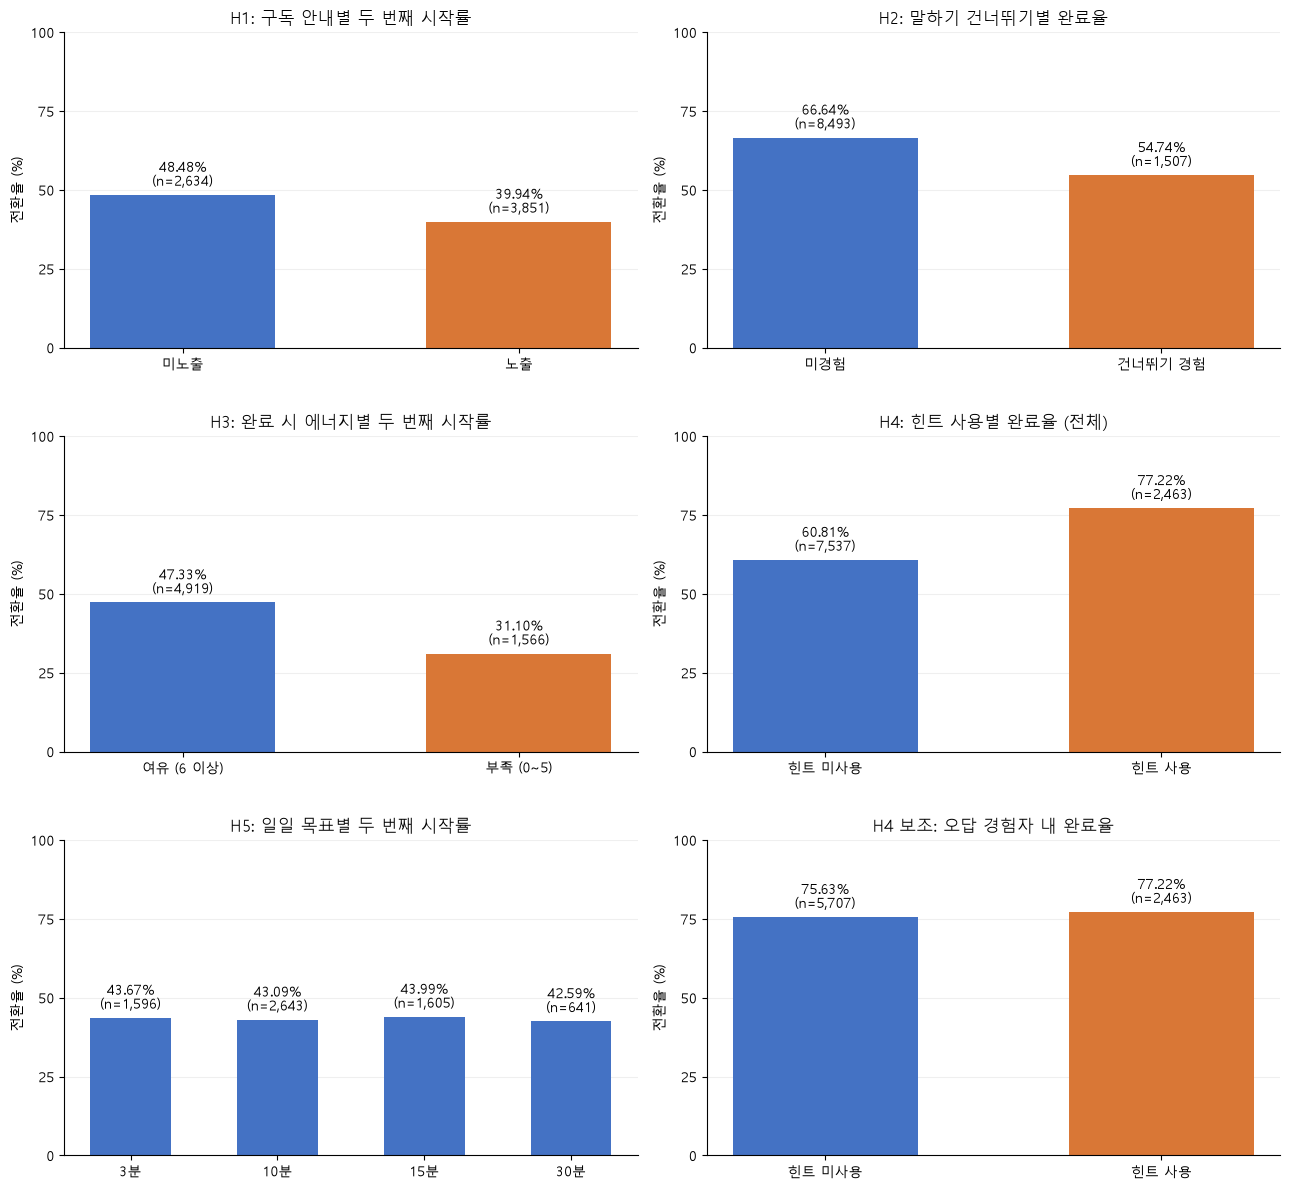

In [12]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 및 음수 기호 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

plot_specs = [
    ("H1: 구독 안내별 두 번째 시작률", h1_summary),
    ("H2: 말하기 건너뛰기별 완료율", h2_summary),
    ("H3: 완료 시 에너지별 두 번째 시작률", h3_summary),
    ("H4: 힌트 사용별 완료율 (전체)", h4_summary),
    ("H5: 일일 목표별 두 번째 시작률", h5_summary),
    ("H4 보조: 오답 경험자 내 완료율", h4_wrong_summary),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for ax, (title, summary) in zip(axes.flat, plot_specs):
    positions = np.arange(len(summary))
    labels = summary.index.astype(str).tolist()
    if title.startswith("H5"):
        labels = [str(goal) + "분" for goal in summary.index]
        colors = ["#4472C4"] * len(summary)
    else:
        colors = ["#4472C4", "#D97736"]

    ax.bar(positions, summary["전환율(%)"], color=colors, width=0.55)
    ax.set_xticks(positions, labels)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_title(title)
    ax.set_ylabel("전환율 (%)")

    for position, (rate, count) in enumerate(zip(summary["전환율(%)"], summary["사용자 수"])):
        ax.text(position, rate + 2, f"{rate:.2f}%\n(n={int(count):,})",
                ha="center", va="bottom", fontsize=10)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout(h_pad=3)
plt.show()


## 7. 결과 종합 및 서비스 개선 방향

### 7.1 주분석 결과

비율 차이는 반올림 전 수치로 계산. H1~H4의 방향과 보정 후 유의성을 함께 확인하며, 모든 결과는 가상 데이터 내 관계.

| 가설 | 집단별 결과 | 차이 | 판단 |
| --- | --- | --- | --- |
| H1 | 구독 미노출 48.48% / 노출 39.94% | 노출자가 8.54%p 낮음 | 가설 방향과 일치 |
| H2 | 말하기 건너뛰기 미경험 66.64% / 경험 54.74% | 경험자가 11.90%p 낮음 | 가설 방향과 일치 |
| H3 | 에너지 여유 47.33% / 부족 31.10% | 부족 집단이 16.23%p 낮음 | 가설 방향과 일치 |
| H4 | 힌트 미사용 60.81% / 사용 77.22% | 사용자가 16.42%p 높음 | 전체 비교에서는 일치하나 보조 비교 확인 필요 |
| H5 | 3분 43.67% / 10분 43.09% / 15분 43.99% / 30분 42.59% | 순차 증가 패턴 없음 | 목표별 차이 근거 부족. 원 p = 0.909 |

### 7.2 보조 비교에서 달라진 해석

- **H2**: 말하기 문제를 조회한 8,751명 내에서도 미경험 74.70% / 경험 54.74%, 차이 **-19.95%p**. 보정 후에도 차이 확인. 다만 학습 진행 정도와 문제 노출 기회가 완전히 같아진 것은 아님.
- **H4**: 오답 경험자 8,170명 내에서는 미사용 75.63% / 사용 77.22%, 차이 **+1.60%p**. 원 p = **0.120**, 보정 p = **0.843**으로 차이의 통계적 근거 부족.
- H4의 전체 차이 +16.42%p를 힌트 효과로 해석하기 어려움. 오답 경험으로 범위를 좁혔을 때 차이가 크게 줄어들어, 비교 대상과 행동 기회의 영향을 먼저 점검할 필요. 보조 비교 역시 무작위 실험과 구분.

### 7.3 개선안 후보와 추가 검증

| 개선 후보 | 이번 분석의 근거 | 이후 검증할 내용 |
| --- | --- | --- |
| 구독 안내의 시점·방식 조정 | H1 노출 집단의 후속 시작률이 낮음 | 안내 시점을 무작위로 배정하고 7일 내 두 번째 시작률 비교 |
| 말하기 문제의 대체 유형 제공 | H2 건너뛰기 집단의 완료율이 낮음 | 말하기가 어려운 상황에서 대체 문제 제공 여부를 무작위 배정하여 완료율 비교 |
| 에너지 부족 시 후속 학습 안내·지원 | H3 부족 집단의 후속 시작률이 낮음 | 부족 집단에 지원 제공 여부를 무작위 배정하여 후속 시작률 비교 |
| 힌트 개선안의 우선순위 재검토 | H4 오답 경험자 내 차이는 작고 불확실 | 오답 후 힌트 안내 여부를 무작위 배정하여 완료율 비교 |

일일 목표 시간 변경은 추가 근거를 확보한 뒤 검토할 항목.

### 7.4 해석의 한계

- H1~H3의 일부 차이는 데이터 생성 시 설정한 확률과 연결된 결과. 실제 서비스에서 동일한 차이가 발생한다는 근거가 아님.
- 구독 안내의 노출 기회는 두 번째 시작까지의 시간에 따라 달라질 수 있음. 현재 노출은 모두 완료 2~15초 후에 기록되지만, 결과 이전 노출만 골라도 이런 시간 차이를 일반적으로 제거할 수 있는 것은 아님.
- 힌트·건너뛰기·오답은 학습 과정에서 발생한 행동. 오래 진행한 사용자에게 행동 기회가 더 많을 수 있으며, 사용자 실력·과정·시작 지점 등의 차이도 남아 있음.
- 유의하지 않다는 결과는 효과가 정확히 0이라는 증명과 구분. 유의한 결과도 실제 개선 효과를 의미하지 않음.
